Check CO2 emissions for ESM.6 scenarios to 2150

In [1]:
import matplotlib.pyplot as plt
import nc_time_axis, cf_units, cftime
import numpy as np
import xarray as xr
import xarray_tools as xrt
import cartopy.crs as ccrs
import iris
from pathlib import Path
from notebook_metadata import create_savefig

savefig = create_savefig(dir='/scratch/tm70/mrd599/plots', nb='check_co2_emissions_2150.ipynb')

In [2]:
from dask.distributed import Client
client = Client(threads_per_worker = 1)

In [3]:
# Chunking experiments
CO2 = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon/CO2_em_anthro/gn/v20250421/CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_19*.nc',
                        chunks={'lat':-1, 'lon':-1}).CO2_em_anthro
CO2_air = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon/CO2_em_AIR_anthro/gn/v20250421/CO2-em-AIR-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_19*.nc',
                        chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro
                        # chunks={'time':12, 'level':-1, 'lat':-1, 'lon':-1}).CO2_em_AIR_anthro
                        # ).CO2_em_AIR_anthro
area_co2 = xrt.get_area(CO2)

/jobfs/181005197.gadi-pbs/ipykernel_3187705/1349397708.py:2: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  CO2 = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon/CO2_em_anthro/gn/v20250421/CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_19*.nc',
/jobfs/181005197.gadi-pbs/ipykernel_3187705/1349397708.py:4: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and ge

In [4]:
co2_g = xrt.global_mean(CO2, area_co2).compute()
co2_ga_tot = xrt.annual_mean(co2_g).sum('sector').compute()

In [5]:
co2_air_g = xrt.global_mean(CO2_air[:120], area_co2).compute()
co2_air_ga_tot = xrt.annual_mean(co2_air_g).sum('level').compute()

Medium session
Single 50 year file, no chunks   73 s, 66s
100 years default chunks  (1,4,180,360)  146
Specifying chunk at load
(12, 8, 360, 720)  26.3
(120, 8, 360, 720)  Memory problems

hist AIR default is 75, 2, 45, 90
10 years 27 s
(12,25,360,720)  42 s, 31 s
(75, 2, 360,720)  10 s
(75, 25, 360,720)  Memory problems

scenario 46, 1, 72, 144
scenario AIR 38, 4, 60, 120, extension  120, 2, 45, 90

In [3]:
CO2 = {}
CO2_air = {}
co2_g = {}
co2_air_g = {}
co2_ga_tot = {}
co2_air_ga_tot = {}
co2_air_ga = {}

# Historical
co2_dir = Path('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon')
co2_files = 'CO2_em_anthro/gn/v20250421/CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_*.nc'
files = co2_dir.glob(co2_files)
# Start in 1850
files = sorted(files)[2:]
print([f.name for f in files])
# CO2['hist'] = xr.open_mfdataset(files, chunks={'time':12, 'sector':-1, 'lat':-1, 'lon':-1}).CO2_em_anthro
CO2['hist'] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_anthro

co2_air_files = 'CO2_em_AIR_anthro/gn/v20250421/CO2-em-AIR-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_*.nc'
files = co2_dir.glob(co2_air_files)
# Start in 1850
files = sorted(files)[2:]
print([f.name for f in files])
# CO2_air['hist'] = xr.open_mfdataset(files, chunks={'time':12, 'level':-1, 'lat':-1, 'lon':-1}).CO2_em_AIR_anthro
CO2_air['hist'] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro

area_co2 = xrt.get_area(CO2['hist'])


['CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_185001-189912.nc', 'CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_190001-194912.nc', 'CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_195001-199912.nc', 'CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_200001-202312.nc']


/jobfs/181031408.gadi-pbs/ipykernel_3256371/3278778374.py:17: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  CO2['hist'] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_anthro


['CO2-em-AIR-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_185001-189912.nc', 'CO2-em-AIR-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_190001-194912.nc', 'CO2-em-AIR-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_195001-199912.nc', 'CO2-em-AIR-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_200001-202312.nc']


/jobfs/181031408.gadi-pbs/ipykernel_3256371/3278778374.py:25: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  CO2_air['hist'] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro


In [4]:
# Scenarios processed for ESM1.6 so far
scenarios = ["h", "hl", "l", "ln", "m", "ml", "vl"]

for s in scenarios:
    co2_dir = Path(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/IIASA-IAMC/IIASA-IAMC-{s}-1-1-1/atmos/mon')
    co2_files = f'CO2_em_anthro/gn/v*/CO2-em-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-{s}-1-1-1_gn_2*.nc'
    files = list(co2_dir.glob(co2_files))
    co2_ext_dir = Path(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/IIASA-IAMC/IIASA-IAMC-{s}-ext-1-1-1/atmos/mon')
    co2_ext_files = f'CO2_em_anthro/gn/v*/CO2-em-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-{s}-ext-1-1-1_gn_2*.nc'
    files += list(co2_ext_dir.glob(co2_ext_files))
    print([f.name for f in files])
    # CO2[s] = xr.open_mfdataset(files, chunks={'time':12, 'sector':-1, 'lat':-1, 'lon':-1}).CO2_em_anthro
    CO2[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_anthro
    # Want to compare to 2151 but input is 5 yearly, so go to 2155
    CO2[s] = CO2[s].sel(time=slice(None, "2155"))

    co2_air_dir = Path(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/IIASA-IAMC/IIASA-IAMC-{s}-1-1-2/atmos/mon')
    co2_air_files = f'CO2_em_AIR_anthro/gn/v*/CO2-em-AIR-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-{s}-1-1-2_gn_2*.nc'
    files = list(co2_air_dir.glob(co2_air_files))
    co2_air_ext_dir = Path(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/IIASA-IAMC/IIASA-IAMC-{s}-ext-1-1-2/atmos/mon')
    co2_air_ext_files = f'CO2_em_AIR_anthro/gn/v*/CO2-em-AIR-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-{s}-ext-1-1-2_gn_2*.nc'
    files += list(co2_air_ext_dir.glob(co2_air_ext_files))
    print([f.name for f in files])
    # CO2_air[s] = xr.open_mfdataset(files, chunks={'time':12, 'level':-1, 'lat':-1, 'lon':-1}).CO2_em_AIR_anthro
    CO2_air[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro
    CO2_air[s] = CO2_air[s].sel(time=slice(None, "2155"))

['CO2-em-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-h-1-1-1_gn_202201-210012.nc', 'CO2-em-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-h-ext-1-1-1_gn_210501-250012.nc']


/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:13: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  CO2[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_anthro
/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:13: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  CO2[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_anthro


['CO2-em-AIR-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-h-1-1-2_gn_202201-210012.nc', 'CO2-em-AIR-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-h-ext-1-1-2_gn_210501-250012.nc']


/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:25: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  CO2_air[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro
/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:25: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  CO2_air[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro


['CO2-em-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-hl-1-1-1_gn_202201-210012.nc', 'CO2-em-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-hl-ext-1-1-1_gn_210501-250012.nc']


...

/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:25: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  CO2_air[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro
/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:25: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  CO2_air[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro


['CO2-em-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-vl-1-1-1_gn_202201-210012.nc', 'CO2-em-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-vl-ext-1-1-1_gn_210501-250012.nc']


/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:13: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  CO2[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_anthro
/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:13: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  CO2[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_anthro


['CO2-em-AIR-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-vl-1-1-2_gn_202201-210012.nc', 'CO2-em-AIR-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-vl-ext-1-1-2_gn_210501-250012.nc']


/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:25: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  CO2_air[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro
/jobfs/181031408.gadi-pbs/ipykernel_3256371/1915084613.py:25: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  CO2_air[s] = xr.open_mfdataset(files, chunks={'lat':-1, 'lon':-1}).CO2_em_AIR_anthro


In [5]:
for run in CO2:
    print(run)
    co2_g[run] = xrt.global_mean(CO2[run], area_co2).compute()
    co2_air_g[run] = xrt.global_mean(CO2_air[run], area_co2).compute()

    co2_ga_tot[run] = xrt.annual_mean(co2_g[run]).sum('sector').compute()
    co2_air_ga_tot[run] = xrt.annual_mean(co2_air_g[run]).sum('level').compute()
    co2_air_ga[run] = xrt.annual_mean(co2_air_g[run]).compute()


hist
h
hl
l
ln
m
ml
vl


In [6]:
co2_ga = {}
co2_g_tot = {}
co2_air_g_tot = {}
for run in CO2:
    co2_ga[run] = xrt.annual_mean(co2_g[run]).compute()
    co2_g_tot[run] = co2_g[run].sum('sector').compute()
    co2_air_g_tot[run] = co2_air_g[run].sum('level').compute()


In [7]:
# Function to change the calendar to noleap to match input4MIPS
def set_noleap(cube):
    time = cube.coord('time')
    origin = time.units.origin
    newunits = cf_units.Unit(origin, calendar='noleap')

    tvals = np.array(time.points)
    has_bnds = not (time.bounds is None)
    if has_bnds:
        tbnds = np.array(time.bounds)
    for i in range(len(time.points)):
        date = time.units.num2date(tvals[i])
        newdate = cftime.DatetimeNoLeap(date.year, date.month, date.day, date.hour, date.minute, date.second)
        tvals[i] = newunits.date2num(newdate)
        if has_bnds:
            for j in range(2):
                date = time.units.num2date(tbnds[i][j])
                newdate = cftime.DatetimeNoLeap(date.year, date.month, date.day, date.hour, date.minute, date.second)
                tbnds[i][j] = newunits.date2num(newdate)
    time.points = tvals
    if has_bnds:
        time.bounds = tbnds
    time.units = newunits

In [10]:
co2_esm16 = {}
cube = iris.load_cube('/g/data/vk83/configurations/inputs/access-esm1p6/modern/historical-emissions/atmosphere/forcing/global.N96/2026.01.07/CO2_fluxes_1849_2023_cmip7.anc')
set_noleap(cube)
co2_esm16['hist'] = xr.DataArray.from_iris(cube).rename({'latitude':'lat', 'longitude':'lon'})
for s in scenarios:
    cube = iris.load_cube(f'/g/data/tm70/pcl851/CMIP7/esm1p6_ancil/2026.10.09/modern/esm-scen7-{s}/atmosphere/forcing/global.N96/2026.10.09/CO2_fluxes_{s}_2022_2150_cmip7.anc')
    set_noleap(cube)
    co2_esm16[s] = xr.DataArray.from_iris(cube).rename({'latitude':'lat', 'longitude':'lon'})

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/iris/common/mixin.py:206: FutureWarning: You are using legacy date precision for Iris units - max precision is seconds. In future, Iris will use microsecond precision - available since cf-units version 3.3 - which may affect core behaviour. To opt-in to the new behaviour, set `iris.FUTURE.date_microseconds = True`.
  warnings.warn(message, category=FutureWarning)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/iris/common/mixin.py:206: FutureWarning: You are using legacy date precision for Iris units - max precision is seconds. In future, Iris will use microsecond precision - available since cf-units version 3.3 - which may affect core behaviour. To opt-in to the new behaviour, set `iris.FUTURE.date_microseconds = True`.
  warnings.warn(message, category=FutureWarning)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/iris/common/m

In [11]:
area_esm15 = xr.open_dataset('/g/data/fs38/publications/CMIP6/CMIP/CSIRO/ACCESS-ESM1-5/piControl/r1i1p1f1/fx/areacella/gn/latest/areacella_fx_ACCESS-ESM1-5_piControl_r1i1p1f1_gn.nc').areacella

In [12]:
co2_esm16_g = {}
for s in co2_esm16:
    co2_esm16_g[s] = xrt.global_mean(co2_esm16[s], area_esm15).compute()

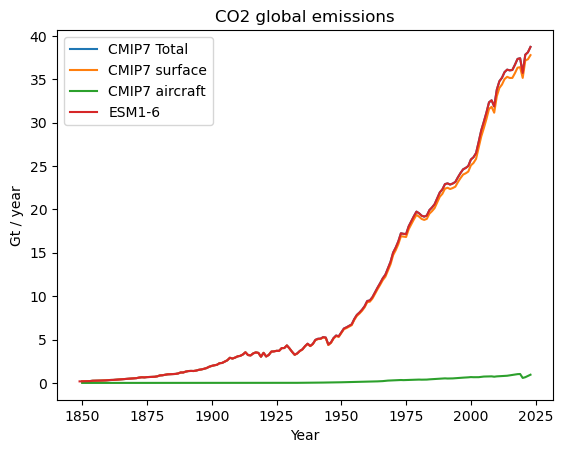

In [13]:
scale = 4 * np.pi * 6.371e6**2 * 365 * 86400 * 1e-12  # Gt/year

fig, axes = plt.subplots()
(scale*(co2_ga_tot['hist']+co2_air_ga_tot['hist'])).plot(label='CMIP7 Total')
(scale*co2_ga_tot['hist']).plot(label='CMIP7 surface')
(scale*co2_air_ga_tot['hist']).plot(label='CMIP7 aircraft')
(scale*xrt.annual_mean(co2_esm16_g['hist'])).plot(label='ESM1-6')
axes.legend()
axes.set_xlabel('Year')
axes.set_ylabel('Gt / year')
axes.set_title('CO2 global emissions')
# axes.set_xlim(2000,2015)
# axes.set_ylim(1.5e-9,2.3e-9)
savefig('co2_emissions_hist.png')

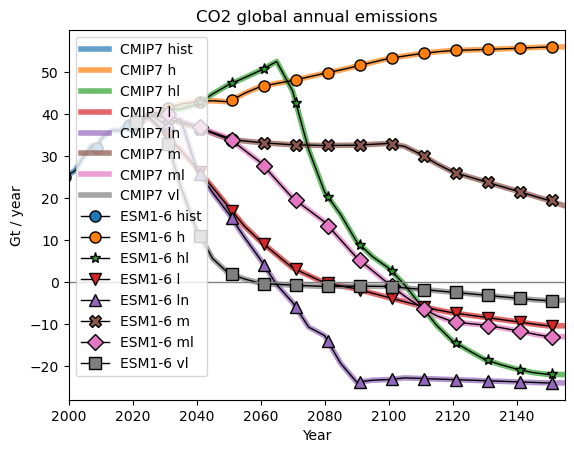

In [24]:
scale = 4 * np.pi * 6.371e6**2 * 365 * 86400 * 1e-12  # Gt/year
markers = ['o', 'o', '*', 'v', '^', "X", "D", "s"]
fig, axes = plt.subplots()
for s in co2_ga_tot:
    (scale*(co2_ga_tot[s]+co2_air_ga_tot[s])).plot(label=f'CMIP7 {s}', lw=4, alpha=0.7) # zorder=0)
i = 0
for s in co2_esm16_g:
    (scale*xrt.annual_mean(co2_esm16_g[s])).plot(label=f'ESM1-6 {s}', lw=1, color='black',
                                                 marker=markers[i], markersize=8, markevery=10,
                                                 markerfacecolor=f'C{i}')
    i += 1
axes.legend()
axes.set_xlabel('Year')
axes.set_ylabel('Gt / year')
axes.set_title('CO2 global annual emissions')
axes.set_xlim(2000,2155)
axes.axhline(color='gray', lw=1)
# axes.set_ylim(1.5e-9,2.3e-9)
savefig('co2_emissions_scenario.png')

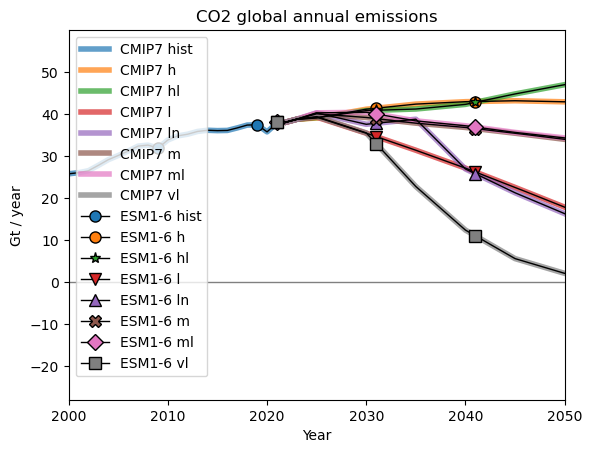

2026-10-12 17:40:36,231 - distributed.nanny - ERROR - Worker process died unexpectedly
Process Dask Worker process (from Nanny):
Process Dask Worker process (from Nanny):
Process Dask Worker process (from Nanny):
2026-10-12 17:40:36,234 - distributed.nanny - ERROR - Worker process died unexpectedly
Process Dask Worker process (from Nanny):
2026-10-12 17:40:36,236 - distributed.nanny - ERROR - Worker process died unexpectedly
Process Dask Worker process (from Nanny):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/asyncio/runners.py", line 118, in run
    return self._loop.run_until_complete(task)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/asyncio/base_events.py", line 691, in run_until_complete
    return future.result()
           ^^^^^^^^^^^^^^^
  File "/g/data/xp65/pu

In [ ]:
scale = 4 * np.pi * 6.371e6**2 * 365 * 86400 * 1e-12  # Gt/year
markers = ['o', 'o', '*', 'v', '^', "X", "D", "s"]
fig, axes = plt.subplots()
for s in co2_ga_tot:
    (scale*(co2_ga_tot[s]+co2_air_ga_tot[s])).plot(label=f'CMIP7 {s}', lw=4, alpha=0.7) # zorder=0)
i = 0
for s in co2_esm16_g:
    (scale*xrt.annual_mean(co2_esm16_g[s])).plot(label=f'ESM1-6 {s}', lw=1, color='black',
                                                 marker=markers[i], markersize=8, markevery=10,
                                                 markerfacecolor=f'C{i}')
    i += 1
axes.legend()
axes.set_xlabel('Year')
axes.set_ylabel('Gt / year')
axes.set_title('CO2 global annual emissions')
axes.set_xlim(2000,2050)
axes.axhline(color='gray', lw=1)
# axes.set_ylim(1.5e-9,2.3e-9)
savefig('co2_emissions_scenario.png')

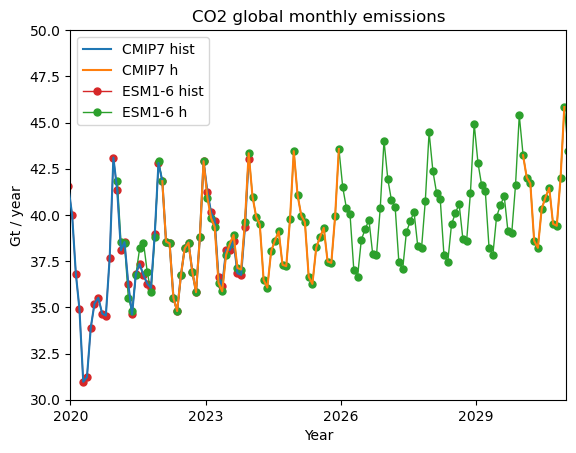

In [12]:
scale = 4 * np.pi * 6.371e6**2 * 365 * 86400 * 1e-12  # Gt/year

fig, axes = plt.subplots()
s = 'hist'
(scale*(co2_g_tot[s]+co2_air_g_tot[s])).plot(label=f'CMIP7 {s}', zorder=100)
s = 'h'
(scale*(co2_g_tot[s]+co2_air_g_tot[s])).sel(time=slice("2022", "2025")).plot(label=f'CMIP7 {s}', zorder=100)
(scale*(co2_g_tot[s]+co2_air_g_tot[s])).sel(time="2030").plot(zorder=100, color='C1')
s = 'hist'
(scale*co2_esm16_g[s]).plot(label=f'ESM1-6 {s}', lw=1, marker='o', markersize=5, markevery=1, color='C3')
s = 'h'
(scale*co2_esm16_g[s]).plot(label=f'ESM1-6 {s}', lw=1, marker='o', markersize=5, markevery=1, color='C2')
axes.legend()
axes.set_xlabel('Year')
axes.set_ylabel('Gt / year')
axes.set_title('CO2 global monthly emissions')
taxis = cf_units.Unit("days since 2000-01-01 00:00", calendar="noleap")
t0 = taxis.date2num(cftime.DatetimeNoLeap(2020,1,1,0,0,0))
t1 = taxis.date2num(cftime.DatetimeNoLeap(2031,1,1,0,0,0))
axes.set_xlim(t0,t1)
axes.set_ylim(30,50)
# axes.set_xlim(2020,2030)
# axes.set_ylim(1.5e-9,2.3e-9)
savefig('co2_monthly_emissions.png')

In [25]:
scale = 86400 * 365
co2_esm16_2050 = {}
co2_esm16_2100 = {}
co2_esm16_2150 = {}
co2_2050 = {}
co2_2100 = {}
co2_2150 = {}
for s in scenarios:
    co2_esm16_2050[s] = scale*xrt.annual_mean(co2_esm16[s].sel(time="2050"))
    co2_esm16_2100[s] = scale*xrt.annual_mean(co2_esm16[s].sel(time="2100"))
    co2_2050[s] = scale*xrt.annual_mean(CO2[s].sel(time="2050").sum('sector')+CO2_air[s].sel(time="2050").sum("level"))
    co2_2100[s] = scale*xrt.annual_mean(CO2[s].sel(time="2100").sum('sector')+CO2_air[s].sel(time="2100").sum("level"))
    co2_esm16_2150[s] = scale*xrt.annual_mean(co2_esm16[s].sel(time="2150"))
    co2_2150[s] = scale*xrt.annual_mean(CO2[s].sel(time="2150").sum('sector')+CO2_air[s].sel(time="2150").sum("level"))

In [14]:
for s in ["h", "hl", "m", "vl"]:
    print(s)
    print(f'{co2_2050[s].min().values:e} {co2_2050[s].max().values:e}')
    print(f'{co2_esm16_2050[s].min().values:e} {co2_esm16_2050[s].max().values:e}')

h
-3.364789e-03 1.242597e+02
-2.314903e-08 1.350107e+01
hl
-7.136739e-03 1.253443e+02
-2.220470e-03 1.729840e+01
m
0.000000e+00 9.577699e+01
0.000000e+00 9.091645e+00
vl
-3.130314e+00 8.333653e+00
-4.859274e-01 1.489957e+00


In [26]:
for s in scenarios:
    print(s)
    print(f'{co2_2100[s].min().values:e} {co2_2100[s].max().values:e}')
    print(f'{co2_esm16_2100[s].min().values:e} {co2_esm16_2100[s].max().values:e}')

h
0.000000e+00 1.713612e+02
0.000000e+00 2.021307e+01
hl
-2.323305e+00 4.152872e+01
-5.615999e-01 6.197074e+00
l
-2.230480e+00 2.492139e+01
-1.113724e+00 7.603577e+00
ln
-1.211272e+01 1.705698e+01
-4.779943e+00 3.568504e+00
m
0.000000e+00 2.028598e+02
0.000000e+00 2.830802e+01
ml
-4.640273e+00 2.383194e+01
-1.826627e+00 3.115183e+00
vl
-1.001782e+00 7.441778e+00
-5.039647e-01 7.826723e-01


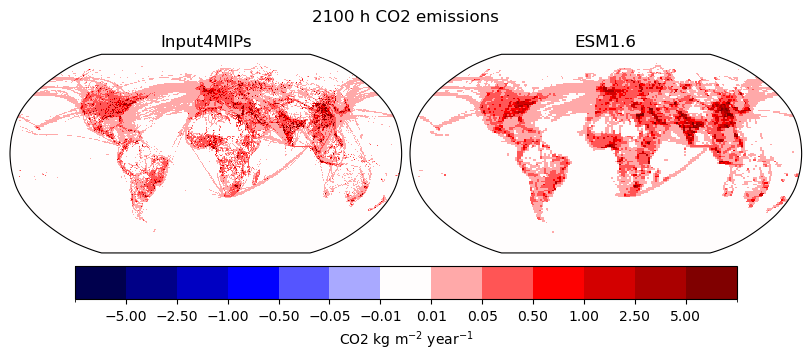

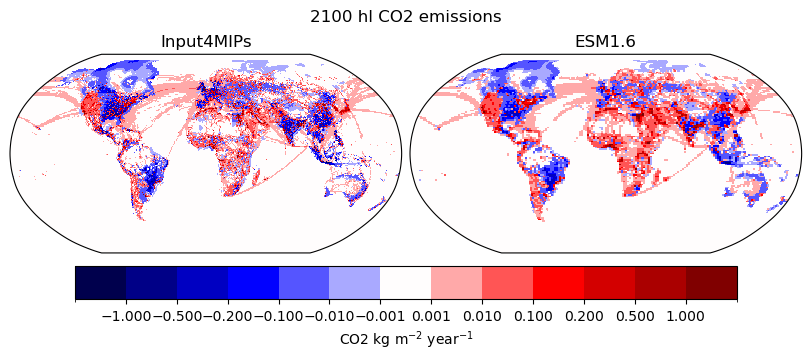

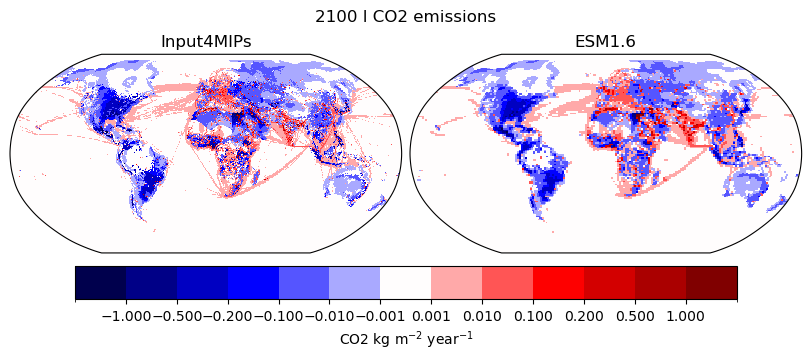

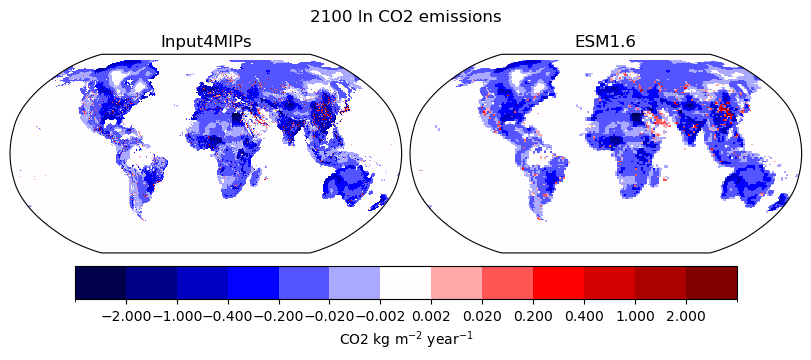

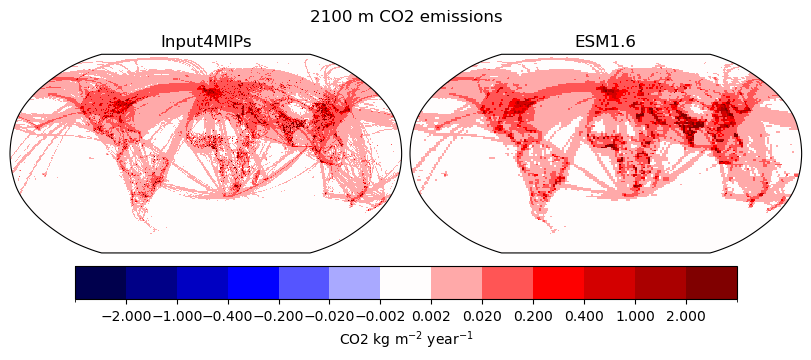

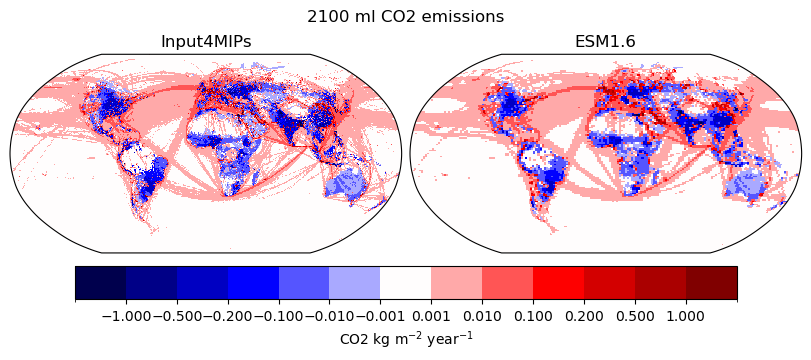

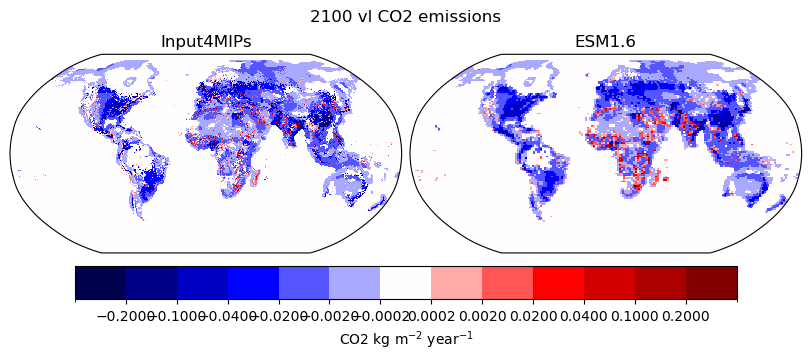

In [29]:
alevels = np.array([-100, -1., -0.5, -0.2, -0.1, -0.01, 0., 0.01,  0.1,  0.2, 0.5, 1., 100])
alevels = np.array([-100., -1., -0.5, -0.2, -0.1, -0.01, -0.001, 0.001, 0.01,  0.1,  0.2, 0.5, 1., 100.])
scale = {'h': 5, 'hl':1, 'l':1, 'ln':2, 'm':2, 'ml':1, 'vl':0.2}
cmap = 'seismic'
for s in scenarios:
    fig, axes = plt.subplots(1,2,layout='constrained', figsize=(8,3.5), subplot_kw={'projection': ccrs.Robinson()})
    axes = axes.flatten()
    levels = scale[s] * alevels
    # print(s, levels)
    fig.suptitle(f'2100 {s} CO2 emissions')
    # Do this first because the input4mips misses white in the middle for some reason
    ax = axes[1]
    p = co2_esm16_2100[s].plot(ax=ax,transform=ccrs.PlateCarree(), add_colorbar=False, levels=levels, cmap=cmap)
    ax.set_title(f'ESM1.6')

    cbar = fig.colorbar(p, ax=axes, orientation='horizontal', extend='neither', ticks=levels[1:-1])
    cbar.set_label(label='CO2 kg m$^{-2}$ year$^{-1}$')

    ax = axes[0]
    co2_2100[s].plot(ax=ax,transform=ccrs.PlateCarree(), add_colorbar=False, levels=levels, colors=p.colorbar.cmap.colors)
    ax.set_title(f'Input4MIPs')

    savefig(f'co2_2100_{s}.png')

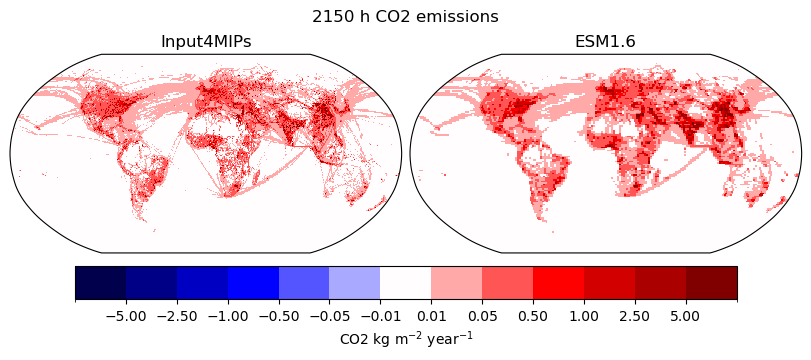

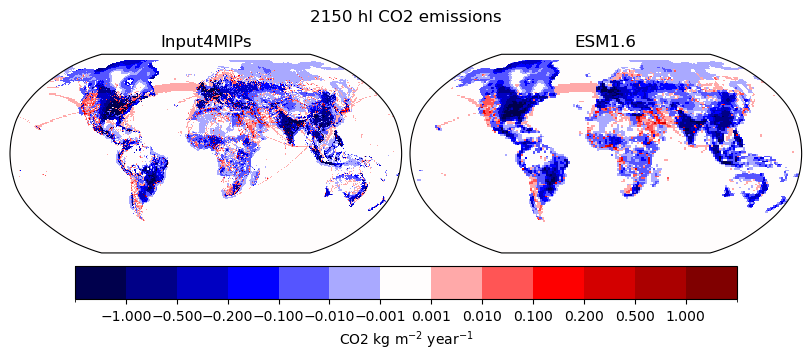

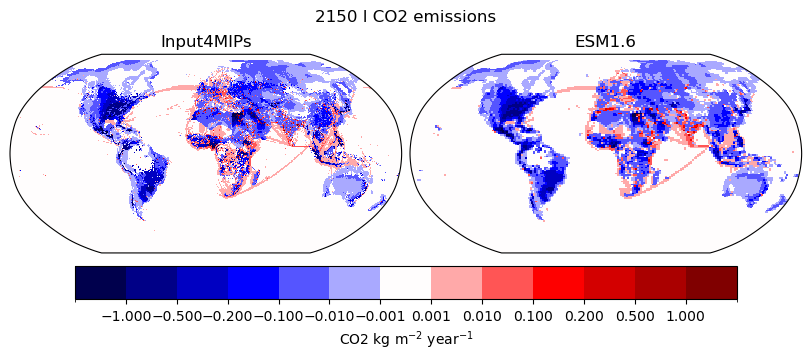

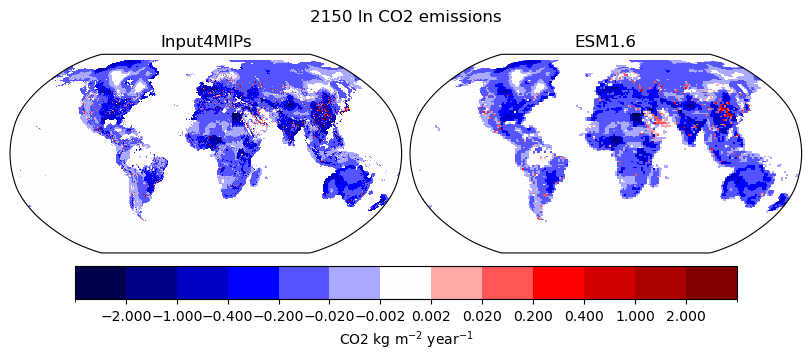

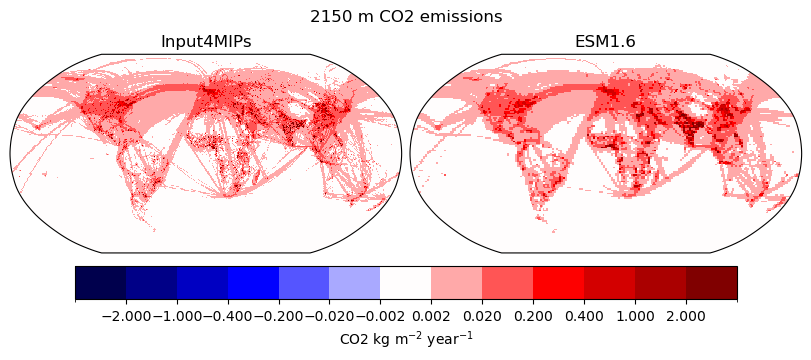

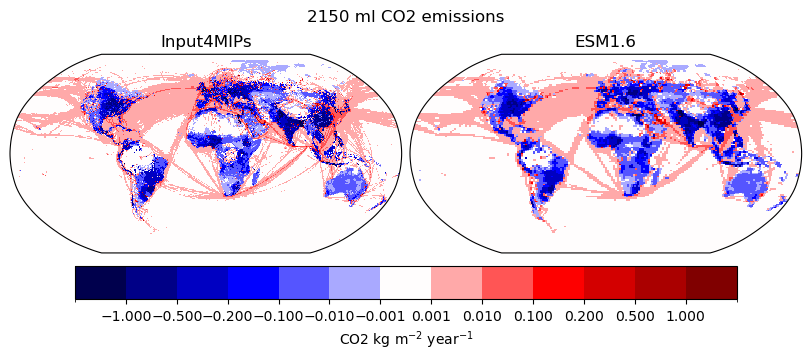

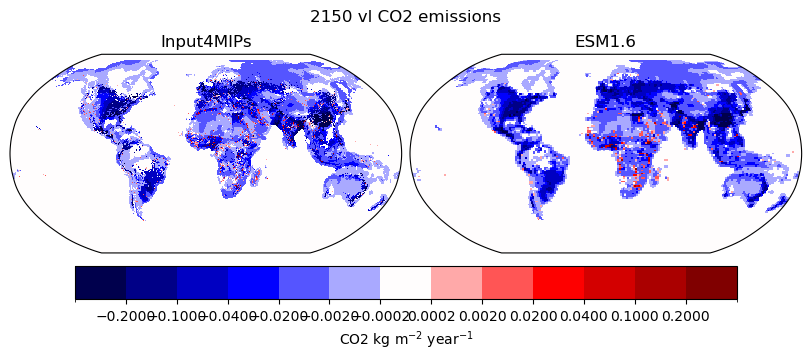

In [30]:
alevels = np.array([-100, -1., -0.5, -0.2, -0.1, -0.01, 0., 0.01,  0.1,  0.2, 0.5, 1., 100])
alevels = np.array([-100., -1., -0.5, -0.2, -0.1, -0.01, -0.001, 0.001, 0.01,  0.1,  0.2, 0.5, 1., 100.])
scale = {'h': 5, 'hl':1, 'l':1, 'ln':2, 'm':2, 'ml':1, 'vl':0.2}
cmap = 'seismic'
for s in scenarios:
    fig, axes = plt.subplots(1,2,layout='constrained', figsize=(8,3.5), subplot_kw={'projection': ccrs.Robinson()})
    axes = axes.flatten()
    levels = scale[s] * alevels
    fig.suptitle(f'2150 {s} CO2 emissions')
    # Do this first because the input4mips misses white in the middle for some reason
    ax = axes[1]
    p = co2_esm16_2150[s].plot(ax=ax,transform=ccrs.PlateCarree(), add_colorbar=False, levels=levels, cmap=cmap)
    ax.set_title(f'ESM1.6')

    cbar = fig.colorbar(p, ax=axes, orientation='horizontal', extend='neither', ticks=levels[1:-1])
    cbar.set_label(label='CO2 kg m$^{-2}$ year$^{-1}$')

    ax = axes[0]
    co2_2150[s].plot(ax=ax,transform=ccrs.PlateCarree(), add_colorbar=False, levels=levels, colors=p.colorbar.cmap.colors)
    ax.set_title(f'Input4MIPs')

    savefig(f'co2_2150_{s}.png')

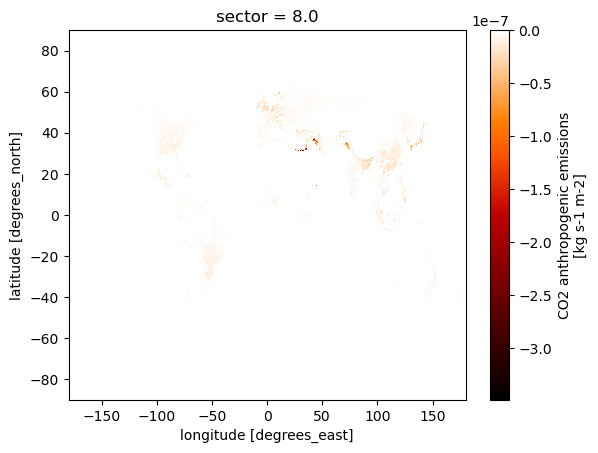

In [37]:
CO2['ln'].sel(time='2100').mean('time')[8].plot(cmap='gist_heat')

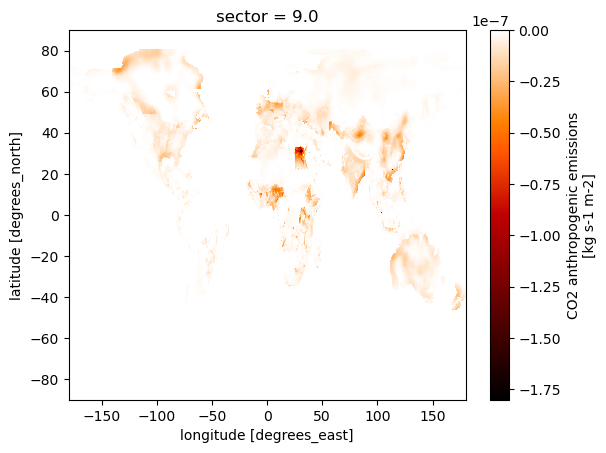

In [38]:
CO2['ln'].sel(time='2100').mean('time')[9].plot(cmap='gist_heat')